# 03 – Network Analysis and Community Detection

**Goal:** find groups of users who are tightly connected through follows, without telling the algorithm anything about their topics.

**Input:** `data/edges_clean.csv`, `data/posts_clean.csv`
**Output:** `data/user_communities.csv`, `data/community_profile.csv`, `network.png`

**Method**
1. Build a graph: users are nodes, follows are edges
2. Describe the graph (size, density, connected components)
3. Detect communities with the Louvain algorithm
4. Check that the result is stable across random seeds
5. Find bridge users who connect communities

**Evaluation:** modularity, community sizes, and stability (NMI between runs).

## 1. Load the data

In [37]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.metrics import normalized_mutual_info_score

edges = pd.read_csv("data/edges_clean.csv")
posts = pd.read_csv("data/posts_clean.csv")

print("edges:", edges.shape)
print("authors with posts:", posts["author_did"].nunique())
edges.head()

edges: (2514, 2)
authors with posts: 14563


,source,target
0,did:plc:syzebrqcvpw4umy7ywb5l5h3,did:plc:adncnwduor7lxtqjxdgusvos
1,did:plc:syzebrqcvpw4umy7ywb5l5h3,did:plc:vkf2hgjur4yamytd2kt7qpet
2,did:plc:syzebrqcvpw4umy7ywb5l5h3,did:plc:5o2acmsdiufwhubmd34kwyii
3,did:plc:syzebrqcvpw4umy7ywb5l5h3,did:plc:ssfob7pv7wm44s3czsx4brse
4,did:plc:syzebrqcvpw4umy7ywb5l5h3,did:plc:dm52j6dz6qymf3ngpyjnyvec


## 2. Build the graph

A follow is **directed** (A follows B does not mean B follows A). We build the directed graph first, then convert it to an **undirected** graph for community detection, since Louvain works on undirected graphs. In the undirected graph a link exists if either user follows the other.

We also count **mutual follows** (both follow each other), which are a stronger sign of a real connection.

In [38]:
G_dir = nx.from_pandas_edgelist(edges, "source", "target", create_using=nx.DiGraph)
G = G_dir.to_undirected()

mutual = sum(1 for u, v in G_dir.edges() if G_dir.has_edge(v, u)) // 2

print("users (nodes):", G.number_of_nodes())
print("links (undirected edges):", G.number_of_edges())
print("mutual follows:", mutual)

users (nodes): 1822
links (undirected edges): 2505
mutual follows: 9


## 3. Describe the network

- **Density:** share of possible links that exist (social networks are very sparse).
- **Average degree:** how many connections a typical user has.
- **Connected components:** separate islands of users with no links between them.

If the largest component holds most users, community detection is meaningful. If it is tiny, collect more authors.

density: 0.0015
average degree: 2.7
max degree: 130
connected components: 14
largest component: 1779 users (98% of the network)


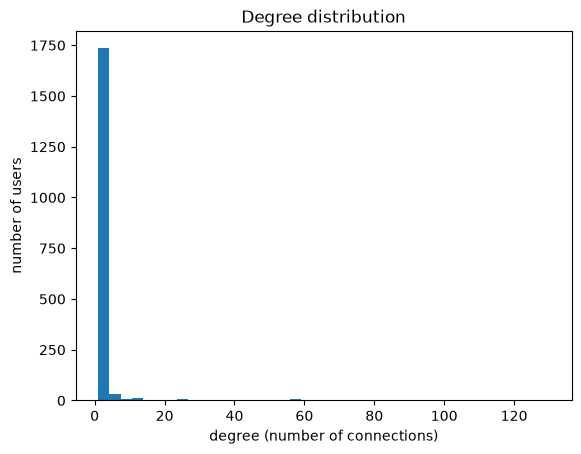

In [39]:
degrees = np.array([d for _, d in G.degree()])
components = sorted(nx.connected_components(G), key=len, reverse=True)

print("density:", round(nx.density(G), 4))
print("average degree:", round(degrees.mean(), 1))
print("max degree:", degrees.max())
print("connected components:", len(components))
print("largest component:", len(components[0]), "users",
      f"({len(components[0]) / G.number_of_nodes():.0%} of the network)")

plt.hist(degrees, bins=40)
plt.xlabel("degree (number of connections)")
plt.ylabel("number of users")
plt.title("Degree distribution")
plt.show()

## 4. Detect communities with Louvain

Louvain moves users between groups to maximize **modularity**: how much denser the links inside groups are compared with a random network with the same degrees.

- Modularity near 0 means no real community structure.
- Values around 0.3 to 0.7 indicate clear communities.

`resolution` controls community size. Higher gives more, smaller communities; lower gives fewer, larger ones.

In [40]:
RESOLUTION = 1.0

communities = nx.community.louvain_communities(G, resolution=RESOLUTION, seed=42)
communities = sorted(communities, key=len, reverse=True)

modularity = nx.community.modularity(G, communities)
print("communities found:", len(communities))
print("modularity:", round(modularity, 3))
print("top 10 community sizes:", [len(c) for c in communities[:10]])

node_to_comm = {}
for cid, members in enumerate(communities):
    for node in members:
        node_to_comm[node] = cid

communities found: 35
modularity: 0.709
top 10 community sizes: [233, 177, 159, 139, 121, 107, 103, 94, 87, 71]


## 5. Check stability

Louvain has a random element. If different seeds give very different groupings, the communities are not trustworthy. We run it with 10 seeds and compare each result with the main run using NMI (1 = identical, near 0 = unrelated). Values above about 0.8 mean the structure is stable.

In [41]:
nodes = list(G.nodes())
base_labels = [node_to_comm[n] for n in nodes]

scores, mods = [], []
for seed in range(10):
    comms = nx.community.louvain_communities(G, resolution=RESOLUTION, seed=seed)
    lab = {n: i for i, c in enumerate(comms) for n in c}
    scores.append(normalized_mutual_info_score(base_labels, [lab[n] for n in nodes]))
    mods.append(nx.community.modularity(G, comms))

print("NMI vs main run: mean", round(np.mean(scores), 3), "min", round(np.min(scores), 3))
print("modularity across seeds: mean", round(np.mean(mods), 3), "std", round(np.std(mods), 3))

NMI vs main run: mean 0.888 min 0.856
modularity across seeds: mean 0.708 std 0.001


## 6. What does each community look like?

For each community we show its size and the **share of tech posts** among its members' posts (from the keyword each post was found with). Near 1 = mostly tech, near 0 = mostly politics, near 0.5 = mixed. The full topic analysis is in notebook 04.

In [42]:
user_tech = (posts.assign(is_tech=(posts["seed_domain"] == "tech"))
                  .groupby("author_did")["is_tech"].mean())
user_posts = posts.groupby("author_did").size()

rows = []
for cid, members in enumerate(communities):
    ms = [m for m in members if m in user_tech.index]
    rows.append({
        "community": cid,
        "users": len(members),
        "users_with_posts": len(ms),
        "tech_share": round(user_tech.loc[ms].mean(), 2) if ms else np.nan,
        "posts": int(user_posts.reindex(ms).sum()) if ms else 0,
    })

profile = pd.DataFrame(rows)
profile[profile["users"] >= 5].head(15)

,community,users,users_with_posts,tech_share,posts
0,0,233,233,0.06,387
1,1,177,177,0.07,286
2,2,159,159,0.07,250
3,3,139,139,0.15,238
4,4,121,121,0.12,262
5,5,107,107,0.03,162
6,6,103,103,0.07,199
7,7,94,94,0.09,166
8,8,87,87,0.04,132
9,9,71,71,0.02,114


## 7. Find bridge users

A bridge user connects different communities. Two measures:

- **External ratio:** share of a user's neighbours in a different community.
- **Betweenness centrality:** how often a user lies on shortest paths between other users (approximated by sampling `k` nodes because the exact version is slow).

A user is a bridge if their external ratio is at least 0.4 and they have at least 5 connections.

In [43]:
def external_ratio(n):
    nbrs = list(G.neighbors(n))
    if not nbrs:
        return 0.0
    return sum(node_to_comm[m] != node_to_comm[n] for m in nbrs) / len(nbrs)

k = min(300, G.number_of_nodes())
betw = nx.betweenness_centrality(G, k=k, seed=42)

users = pd.DataFrame({
    "author_did": nodes,
    "community": [node_to_comm[n] for n in nodes],
    "degree": [G.degree(n) for n in nodes],
    "betweenness": [betw[n] for n in nodes],
    "external_ratio": [external_ratio(n) for n in nodes],
})
users["tech_share"] = users["author_did"].map(user_tech)
users["is_bridge"] = (users["external_ratio"] >= 0.4) & (users["degree"] >= 5)

print("bridge users:", int(users["is_bridge"].sum()), "of", len(users))
users.sort_values("betweenness", ascending=False).head(10)[
    ["community", "degree", "betweenness", "external_ratio", "tech_share", "is_bridge"]]

bridge users: 33 of 1822


,community,degree,betweenness,external_ratio,tech_share,is_bridge
79,4,130,0.172432,0.346154,0.166667,False
1476,5,121,0.131213,0.123967,0.000000,False
453,3,112,0.119736,0.437500,0.666667,True
1040,8,119,0.117182,0.277311,0.000000,False
147,11,88,0.100291,0.261364,0.000000,False
851,9,94,0.086976,0.255319,0.250000,False
1341,6,82,0.077770,0.317073,0.000000,False
1239,2,96,0.072857,0.427083,0.111111,True
705,0,87,0.068212,0.275862,0.000000,False
1297,0,82,0.066552,0.280488,0.000000,False


## 8. Visualize the network

The 8 largest communities are drawn in different colors. Node size reflects degree. Labels are left out on purpose so no individual user is identifiable. If the network has more than 3,000 nodes in these communities, only the first 3,000 are drawn.

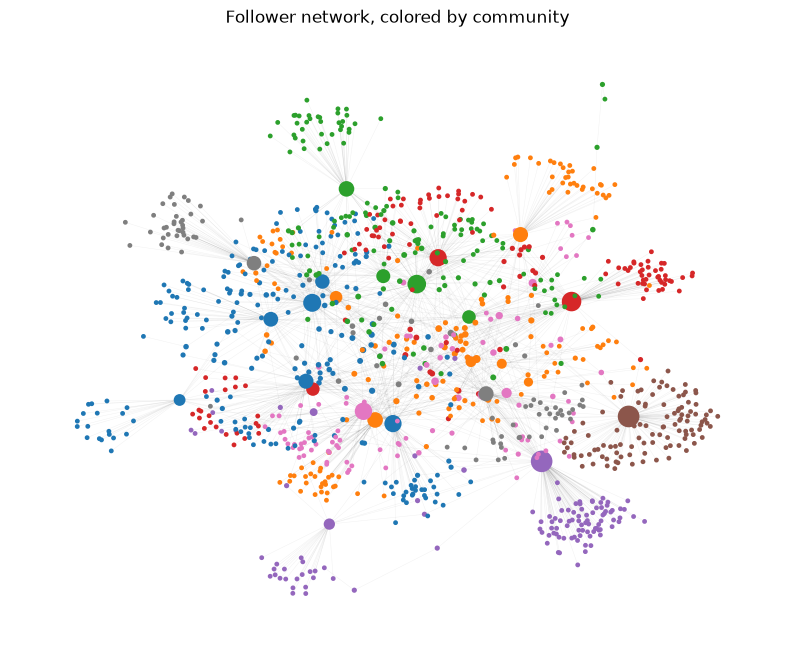

In [44]:
top_ids = list(range(min(8, len(communities))))
keep = [n for n in G.nodes() if node_to_comm[n] in top_ids]
if len(keep) > 3000:
    keep = keep[:3000]
H = G.subgraph(keep)

pos = nx.spring_layout(H, seed=42, k=0.15)
cmap = plt.get_cmap("tab10")
colors = [cmap(node_to_comm[n] % 10) for n in H.nodes()]
sizes = [10 + 2 * H.degree(n) for n in H.nodes()]

plt.figure(figsize=(10, 8))
nx.draw_networkx_edges(H, pos, alpha=0.05, width=0.4)
nx.draw_networkx_nodes(H, pos, node_color=colors, node_size=sizes, linewidths=0)
plt.axis("off")
plt.title("Follower network, colored by community")
plt.savefig("network.png", dpi=200, bbox_inches="tight")
plt.show()

## 9. Save the results

`user_communities.csv` is the input to notebook 04. Each user gets an anonymous ID (`anon_id`), which should be used in every chart or report instead of real handles.

In [45]:
users = users.sort_values("community").reset_index(drop=True)
users["anon_id"] = ["U" + str(i).zfill(5) for i in range(len(users))]

users.to_csv("data/user_communities.csv", index=False)
profile.to_csv("data/community_profile.csv", index=False)

print("saved:", users.shape)

saved: (1822, 8)


## Summary

- Network: **N** users and **E** links; density **D**; the largest component holds **P%** of users.
- Louvain found **K** communities with modularity **M**; stability across 10 seeds gave mean NMI **S**.
- The largest communities are (describe 3 or 4 in your own words, using `tech_share`).
- **B** users were flagged as bridges (external ratio ≥ 0.4, degree ≥ 5).
- **Limitations:**
  - Only follow links among users who posted about our keywords are included, so the network is a subset of Bluesky.
  - Following does not mean agreeing with someone.
  - Louvain results depend on the `resolution` setting, fixed at 1.0.